# 03. A vida de um contrato do MCMV-Entidades: projeto, cláusula suspensiva, obra e famílias

No FAR a vida do contrato tem três fases (pré-obra, obra, pós-obra). No Entidades há uma a mais, antes de tudo: o **contrato de projeto**. Se a entidade não tem terreno e projeto aprovados, o FDS financia primeiro a aquisição do terreno e a elaboração do projeto (um APF), e só depois vem o **contrato de obra** (outro APF). Este notebook organiza cada APF do Novo MCMV-Entidades nessa escala temporal:

1. **Projeto**: do contrato de projeto aos 100% do projeto (terreno comprado, projeto aprovado), quando o contrato de obra pode nascer.
2. **Pré-obra**: do contrato de obra ao primeiro físico medido. Inclui a cláusula suspensiva (o INT059 marca 60 contratos "não iniciados com cláusula suspensiva") e a primeira parcela na conta da CRE.
3. **Obra**: do primeiro físico aos 100%. É onde a curva S vive. A carteira nova ainda não tem obra concluída, então a duração vem do legado PMCMV-E.
4. **Pós-obra**: dos 100% à alienação (contrato da família com o FDS) e à entrega. No legado, é onde mais obras param.

Depois, a carteira sobre essa escala, a pergunta "em que fase o atraso acontece e por quê" (com os motivos que o banco traz, do legado e do trabalho social) e o caso da União por Moradia Popular da Paraíba, que tem um projeto concluído e duas obras de 256 UH que o INT059 chama de paralisadas.

**De onde vem cada marco (tudo do banco do Lab, 10.0.0.50):**

| Marco | Coluna | Tabela |
|---|---|---|
| Contratação | `dt_contratacao` | `prata.prata_fds_empreendimento` (cadastro PJ do MONIT) |
| Fase do contrato (projeto ou obra) e cláusula suspensiva | `fase_contrato`, `situacao_gefus` | `prata.prata_fds_int_059_caixa_pj` (INT059, jun/2026) |
| Primeira liberação e primeiro pagamento de obra | `dt_liberacao`, `vr_pago_obra` | `prata.prata_fds_financeiro_mensal` (livro-razão) |
| Primeiro físico medido e 100% | `percentual_execucao_fisica`, `pc_obra_realizada` | `prata.prata_hist_fds_empreendimento` (Dados Prioritários, obra mensal, INT059) |
| Promessa de conclusão | `dt_previsao_conclusao` | cadastro PJ |
| Contrato das famílias e alienação | `dt_primeira_assinatura_pf`, `qt_uh_alienadas` | `prata.prata_fds_obra_mensal` |
| Legado: contratação, conclusão, entrega, paralisação, motivo | `dt_contratacao`, `dt_conclusao_obra`, `dt_entrega_uh`, `status_operacional`, `motivo_paralisacao` | `prata.prata_hist_fds_empreendimento` (INT059 e Dados Prioritários) |

**Duas ressalvas.** O cadastro PJ traz `dt_inicio_obra` igual à data de contratação em todos os 364 contratos, então o início da obra precisa ser observado (primeiro físico medido ou primeiro pagamento de obra). E a cláusula suspensiva só existe como situação atual no INT059, sem data de início nem de fim: dá para saber quem está nela hoje, não quanto tempo cada contrato ficou.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: resumo da auditoria deste notebook (30/10/2026)</b><ul style="margin:6px 0 0 0"><li>Todos os marcos de data vêm do banco (cadastro PJ, INT059, livro-razão, eixo histórico, obra mensal). O legado PMCMV-E (contratos de 2009 a 2019) é usado como referência de duração porque a carteira nova não tem obra concluída: é uma escolha deste notebook, marcada onde entra.</li><li>Não vêm do banco: a data de hoje (31/08/2026), as réguas de atraso por fase (p80 da própria carteira, 12 meses em cláusula suspensiva, p20 da curva S, promessa vencida), a regra que atribui a fase de cada APF em cada mês, o mapa de motivo de paralisação para fase e a leitura do caso da UMP-PB.</li></ul></div>

In [1]:
import sys; sys.path.insert(0, "../..")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from src import db

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 60)
INTERIM = Path("../../data/interim"); INTERIM.mkdir(parents=True, exist_ok=True); OUT = Path("../../output"); OUT.mkdir(exist_ok=True)
HOJE = pd.Timestamp("2026-08-31")
C = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100", "roxo": "#4a3aa7", "cinza": "#9a9892"}
STATUS = {"bom": "#0ca30c", "atencao": "#fab219", "serio": "#ec835a", "critico": "#d03b3b", "neutro": "#9a9892"}
FASE_C = {"Projeto em elaboração": "#fbd9cc", "Projeto concluído (aguarda contrato de obra)": C["laranja"], "Pré-obra (sem físico medido)": "#9ec5f4", "Obra": C["azul"], "Pós-obra (100% sem famílias)": C["roxo"], "Famílias com contrato": STATUS["bom"]}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e2",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#c9c8c4", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False, "axes.axisbelow": True})
def num(x): return f"{x:,.0f}".replace(",", ".")
def brl(x, casas=2):
    if x is None or (isinstance(x, float) and np.isnan(x)): return "–"
    for div, suf in [(1e9, " bi"), (1e6, " mi"), (1e3, " mil")]:
        if abs(x) >= div: return ("R$ " + f"{x/div:,.{casas}f}" + suf).replace(",", "X").replace(".", ",").replace("X", ".")
    return ("R$ " + f"{x:,.0f}").replace(",", "X").replace(".", ",").replace("X", ".")
def meses(a, b): return (b - a).dt.days / 30.44
def rotular_barras(ax, fmt=num, fontsize=9, horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v == 0 or np.isnan(v): continue
        if horizontal: ax.annotate(fmt(v), (v, p.get_y() + p.get_height()/2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=fontsize, color="#52514e")
        else: ax.annotate(fmt(v), (p.get_x() + p.get_width()/2, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=fontsize, color="#52514e")
def cache(nome, sql):
    f = INTERIM / f"{nome}.parquet"
    if f.exists(): return pd.read_parquet(f)
    df = db.ler_sql(sql); df.to_parquet(f); return df
def regua(df, col_mes, val="pct", min_n=15):
    g = df.groupby(col_mes)[val]
    r = pd.DataFrame({"n": g.size(), "p20": g.quantile(.2), "p80": g.quantile(.8), "media_aparada": g.apply(lambda s: s[(s >= s.quantile(.2)) & (s <= s.quantile(.8))].mean())})
    return r[r.n >= min_n]
print("conectado em", db.HOST)

conectado em 10.0.0.50


## 1. Os marcos de cada contrato

In [2]:
emp = cache("fds_empreendimento", "select * from prata.prata_fds_empreendimento")
for c in ["dt_contratacao","dt_previsao_conclusao","dt_ultima_liberacao"]: emp[c] = pd.to_datetime(emp[c])
emp.loc[emp.dt_previsao_conclusao < "2000-01-01", "dt_previsao_conclusao"] = pd.NaT
hist = cache("fds_hist_serie_novo", """
select apf, dt_referencia, fonte_serie, percentual_execucao_fisica, pc_obra_realizada, pc_obra_prevista, valor_desembolsado, status_operacional, quantidade_uh_entregues
from prata.prata_hist_fds_empreendimento where apf in (select apf from prata.prata_fds_empreendimento)""")
hist["mes"] = pd.to_datetime(hist.dt_referencia); hist["pct"] = hist.percentual_execucao_fisica.fillna(hist.pc_obra_realizada)
sm = hist.dropna(subset=["pct"]).groupby(["apf","mes"]).agg(pct=("pct","max"), pct_prev=("pc_obra_prevista","max")).reset_index()
fin = cache("fds_financeiro", """
select apf, dt_liberacao, dt_movimento, co_tipo_movimento, ic_credito, vr_liberado, vr_movimento, vr_pago_obra, vr_pago_terreno, vr_pago_trabalho_social, vr_pago_projeto, vr_pago_aporte, vr_pago_incc, vr_pago_legalizacao, vr_pago_seguranca
from prata.prata_fds_financeiro_mensal""")
fin = fin[fin.ic_credito == "0"].copy(); fin["dt_liberacao"] = pd.to_datetime(fin.dt_liberacao); fin["liberado"] = fin.vr_liberado.abs(); fin["pago_obra"] = fin.vr_pago_obra.abs(); fin["apf_raiz"] = fin.apf.str[-6:]
obra = cache("fds_obra_mensal", """
select apf, co_situacao_operacao, dt_alteracao_situacao, pct_obra_prevista, pct_obra_realizada, qt_uh_alienadas, qt_uh_a_alienar, qt_uh_concluidas, qt_uh_sem_habitese, dt_primeira_assinatura_pf, dt_ultima_assinatura_pf,
       dt_previsao_entrega, dt_conclusao_obra, dt_legalizacao, dt_entrega, dt_paralisacao, co_classificacao_paralisado, detalhe_paralisacao, dt_movimento
from prata.prata_fds_obra_mensal""")
for c in ["dt_primeira_assinatura_pf","dt_previsao_entrega","dt_movimento"]: obra[c] = pd.to_datetime(obra[c])
int059 = cache("fds_int059_novo", """
select apf, situacao_gefus, fase_contrato, regime_construcao, tipo_terreno, tipologia as tipologia_int059, qt_uh_financiadas, pct_obra_realizado, vr_liberado as vr_liberado_int059, dt_contratacao as dt_contratacao_int059, dt_inicio_obra as dt_inicio_obra_int059, dt_termino_obra, dt_movimento
from prata.prata_fds_int_059_caixa_pj where selecao_pmcmv_e = 'NOVO PMCMV-E'""")
int059["dt_termino_obra"] = pd.to_datetime(int059.dt_termino_obra)
sit = cache("seed_far_situacao_obra", "select co_situacao_obra, situacao_obra from seeds.far_situacao_obra").astype({"co_situacao_obra": int}).set_index("co_situacao_obra").situacao_obra.to_dict()

m = emp[["apf","empreendimento_nome","municipio","uf","eo_nome","eo_cnpj","fase_contrato","situacao_gefus","co_situacao_operacao","quantidade_uh","valor_financiamento_fds","valor_desembolsado",
         "percentual_execucao_fisica","percentual_obra_prevista","percentual_execucao_financeira","dt_contratacao","dt_previsao_conclusao"]].copy()
m["apf_raiz"] = m.apf.str[:6]; m["situacao_monit"] = m.co_situacao_operacao.map(sit)
g = sm.groupby("apf")
m["m_fis0"] = m.apf.map(sm[sm.pct > 0].groupby("apf").mes.min()); m["m_100"] = m.apf.map(sm[sm.pct >= 99.99].groupby("apf").mes.min())
m["m_ult"] = m.apf.map(g.mes.max()); m["pct_ult"] = m.apf.map(sm.sort_values("mes").groupby("apf").pct.last())
m["m_lib0"] = m.apf_raiz.map(fin.groupby("apf_raiz").dt_liberacao.min()); m["m_obra0"] = m.apf_raiz.map(fin[fin.pago_obra > 0].groupby("apf_raiz").dt_liberacao.min())
m = m.merge(obra[["apf","dt_primeira_assinatura_pf","qt_uh_alienadas","dt_previsao_entrega"]].rename(columns={"dt_primeira_assinatura_pf": "pf0", "dt_previsao_entrega": "prev_ent_monit"}), on="apf", how="left").merge(int059[["apf","dt_termino_obra"]], on="apf", how="left")
m["susp"] = m.situacao_gefus == "NAO_INICIADA_CLAUSULA_SUSPENSIVA"; m["paralisada"] = m.situacao_gefus == "PARALISADA"
m["inicio_fisico"] = m.m_fis0.fillna(m.m_obra0.dt.to_period("M").dt.to_timestamp())      # 1º físico medido; reserva: 1º pagamento de obra
m["fim_obra"] = m.m_100.where(m.fase_contrato == "OBRA"); m["projeto_concluido"] = m.m_100.where(m.fase_contrato == "PROJETO")
m["entrada_familias"] = m.pf0.where(m.qt_uh_alienadas > 0)
m.to_parquet(INTERIM / "fds_marcos_apf.parquet")
cob = m.groupby("fase_contrato")[["dt_contratacao","m_lib0","m_obra0","m_fis0","inicio_fisico","m_100","pf0","entrada_familias"]].count()
cob.columns = ["contratação","1ª liberação","1º pagamento de obra","1º físico medido","início físico (ou reserva)","100%","1º contrato PF","famílias com contrato"]
display(cob)
print(f"{len(m)} contratos; {m.susp.sum()} em cláusula suspensiva hoje; {m.paralisada.sum()} paralisados; {m.inicio_fisico.notna().sum()} com início físico observado; {m.m_100.notna().sum()} chegaram a 100% (todos contratos de projeto); {m.entrada_familias.notna().sum()} com famílias contratadas (lotes).")

,contratação,1ª liberação,1º pagamento de obra,1º físico medido,início físico (ou reserva),100%,1º contrato PF,famílias com contrato
fase_contrato,,,,,,,,
OBRA,181,75,74,78,78,0,4,4
PROJETO,182,122,30,107,109,2,0,0


364 contratos; 60 em cláusula suspensiva hoje; 4 paralisados; 187 com início físico observado; 2 chegaram a 100% (todos contratos de projeto); 4 com famílias contratadas (lotes).


## 2. Quanto dura cada fase

Para a carteira nova dá para medir o que já aconteceu: a fase de projeto (contratação do projeto → 100%) e a pré-obra (contratação da obra → primeiro físico). Obra e pós-obra ainda não terminaram para ninguém, então a referência é o legado PMCMV-E: 553 contratos de 2009 a 2019 com datas de contratação, conclusão e entrega no INT059. Fases em andamento ficam fora da mediana (seriam censuradas), mas aparecem na contagem.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: o legado como régua, e as datas de início que não servem</b><ul style="margin:6px 0 0 0"><li>A duração da obra e do pós-obra vem do legado PMCMV-E (contratos de 2009 a 2019, <code>prata_hist_fds_empreendimento</code>, fonte INT059), porque nenhum contrato de obra novo chegou a 100%. Usar o legado como referência é uma escolha deste notebook: o Novo MCMV tem regras diferentes (parcelas antecipadas por porte, 24 + 12 meses de prazo, Portaria 959/2025) e o legado inclui obras que ficaram paradas anos.</li><li>No cadastro PJ e no INT059 a data de início da obra é igual (ou quase) à de contratação em todos os contratos novos, e em 78% do legado. Por isso a obra do legado é medida da contratação à conclusão, e o início físico da carteira nova é observado na série (primeiro mês com físico > 0; reserva: primeiro pagamento de obra no livro-razão).</li><li><b>Como levar ao banco:</b> coluna <code>dt_inicio_fisico_observado</code> na série do FDS (a criar, no molde da <code>ouro_far_serie_mensal_apf</code>) e pedido ao GEFUS da data real de início de obra (ordem de serviço) no MONIT_CAD_PJ_FDS.</li></ul></div>

,contratos,p25,mediana,p75,em andamento (não concluída)
Projeto: contratação → 100% do projeto (carteira nova),2.0,10.7,11.4,12.2,180.0
Pré-obra: contratação → 1º físico (carteira nova),78.0,6.0,8.1,10.1,103.0
Obra: contratação → conclusão (legado),245.0,23.0,31.0,61.0,78.0
Pós-obra: conclusão → entrega (legado),159.0,2.0,3.9,7.1,NaN
Total: contratação → entrega (legado),372.0,26.3,37.8,61.0,NaN


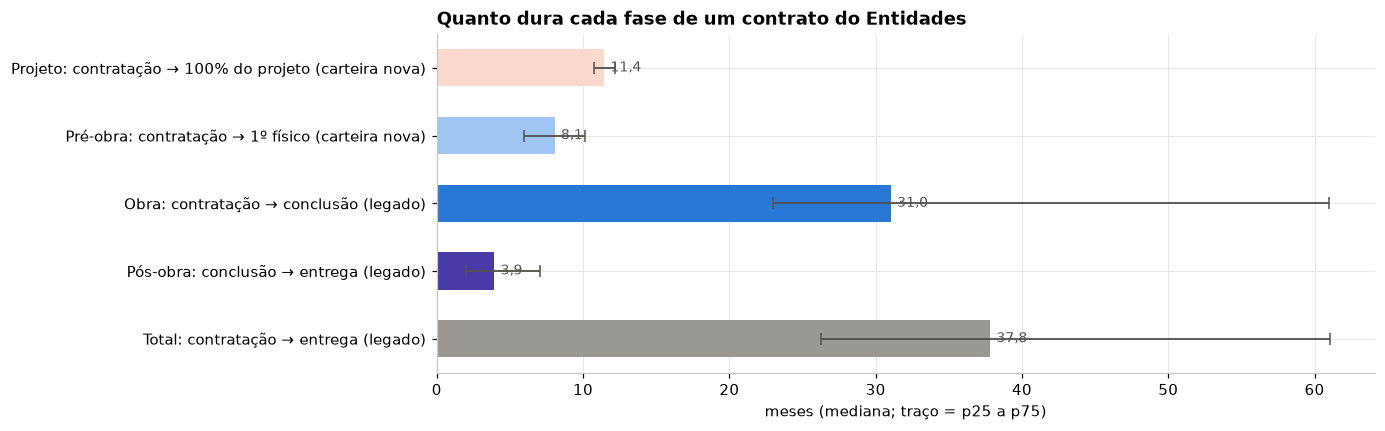

Projetos ainda em elaboração: 180 (há 14.9 meses, mediana). Contratos de obra sem físico: 103 (há 10.9 meses). Obras em execução: 78 (há 6.0 meses).


In [3]:
m["d_proj"] = meses(m.dt_contratacao, m.projeto_concluido)
m["d_pre"] = meses(m.dt_contratacao, m.inicio_fisico).where(m.fase_contrato == "OBRA")
hoje_s = pd.Series(HOJE, index=m.index)
m["d_proj_aberta"] = np.where((m.fase_contrato == "PROJETO") & m.projeto_concluido.isna(), meses(m.dt_contratacao, hoje_s), np.nan)
m["d_pre_aberta"] = np.where((m.fase_contrato == "OBRA") & m.inicio_fisico.isna(), meses(m.dt_contratacao, hoje_s), np.nan)
m["d_obra_aberta"] = np.where((m.fase_contrato == "OBRA") & m.inicio_fisico.notna() & m.fim_obra.isna(), meses(m.inicio_fisico, hoje_s), np.nan)
leg = cache("fds_legado_ultimo", """
select distinct on (apf) apf, nome_empreendimento, uf, municipio, quantidade_uh, quantidade_uh_entregues, status_operacional, situacao_canonica,
       dt_contratacao, dt_inicio_obra, dt_conclusao_obra, dt_entrega_uh, dt_paralisacao, percentual_execucao_fisica, valor_contratado, valor_desembolsado, motivo_paralisacao, dt_referencia
from prata.prata_hist_fds_empreendimento where fonte_serie = 'sftp' and apf not in (select apf from prata.prata_fds_empreendimento)
order by apf, dt_referencia desc""")
for c in ["dt_contratacao","dt_inicio_obra","dt_conclusao_obra","dt_entrega_uh","dt_paralisacao","dt_referencia"]: leg[c] = pd.to_datetime(leg[c])
leg = leg[leg.dt_contratacao < "2024-01-01"].copy()
leg["d_obra"] = meses(leg.dt_contratacao, leg.dt_conclusao_obra); leg["d_pos"] = meses(leg.dt_conclusao_obra, leg.dt_entrega_uh); leg["d_total"] = meses(leg.dt_contratacao, leg.dt_entrega_uh)
leg.loc[leg.d_pos < 0, "d_pos"] = np.nan
fases = pd.DataFrame({"Projeto: contratação → 100% do projeto (carteira nova)": m.d_proj, "Pré-obra: contratação → 1º físico (carteira nova)": m.d_pre,
                      "Obra: contratação → conclusão (legado)": leg.d_obra, "Pós-obra: conclusão → entrega (legado)": leg.d_pos, "Total: contratação → entrega (legado)": leg.d_total})
res = fases.describe(percentiles=[.25, .5, .75]).T[["count","25%","50%","75%"]].rename(columns={"count": "contratos", "25%": "p25", "50%": "mediana", "75%": "p75"})
res["em andamento (não concluída)"] = [m.d_proj_aberta.notna().sum(), m.d_pre_aberta.notna().sum(), m.d_obra_aberta.notna().sum(), np.nan, np.nan]
display(res.round(1))
fig, ax = plt.subplots(figsize=(11, 4))
r = res[::-1]
cores = [FASE_C["Projeto em elaboração"], FASE_C["Pré-obra (sem físico medido)"], FASE_C["Obra"], FASE_C["Pós-obra (100% sem famílias)"], C["cinza"]][::-1]
ax.barh(r.index, r.mediana, color=cores, height=0.55)
ax.errorbar(r.mediana, range(len(r)), xerr=[r.mediana - r.p25, r.p75 - r.mediana], fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
ax.set_xlabel("meses (mediana; traço = p25 a p75)"); ax.set_title("Quanto dura cada fase de um contrato do Entidades")
rotular_barras(ax, fmt=lambda v: f"{v:.1f}".replace(".", ","), horizontal=True)
plt.show()
print(f"Projetos ainda em elaboração: {m.d_proj_aberta.notna().sum()} (há {np.nanmedian(m.d_proj_aberta):.1f} meses, mediana). Contratos de obra sem físico: {m.d_pre_aberta.notna().sum()} (há {np.nanmedian(m.d_pre_aberta):.1f} meses). Obras em execução: {m.d_obra_aberta.notna().sum()} (há {np.nanmedian(m.d_obra_aberta):.1f} meses).")

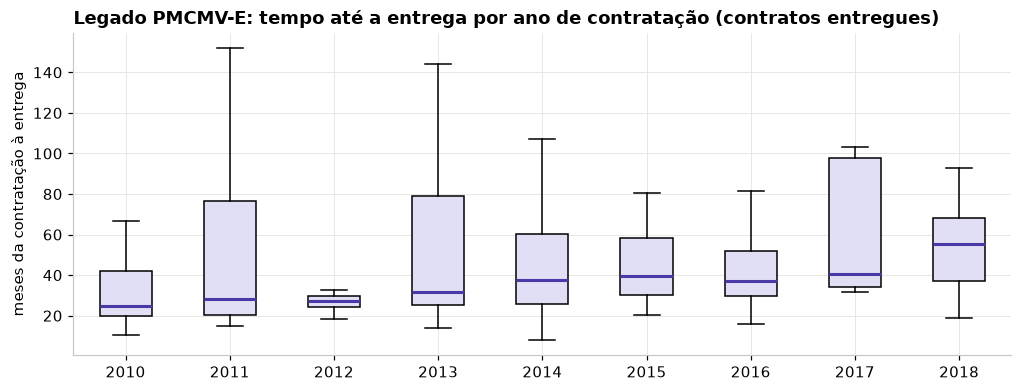

dt_contratacao,2010,2011,2012,2013,2014,2015,2016,2017,2018
contratos,59.0,29.0,31.0,64.0,101.0,60.0,93.0,13.0,91.0
entregues,44.0,26.0,18.0,28.0,70.0,36.0,58.0,9.0,74.0
mediana_meses,25.0,28.0,27.0,32.0,38.0,39.0,37.0,40.0,55.0
paralisadas,9.0,0.0,5.0,14.0,11.0,9.0,15.0,3.0,8.0
canceladas,1.0,0.0,0.0,3.0,5.0,5.0,7.0,0.0,5.0


In [4]:
# O legado ano a ano: da contratação à entrega
la = leg[leg.dt_contratacao.dt.year.between(2010, 2018)]
fig, ax = plt.subplots(figsize=(11, 3.8))
anos = sorted(la.dt_contratacao.dt.year.unique())
ax.boxplot([la[la.dt_contratacao.dt.year == a].d_total.dropna() for a in anos], tick_labels=anos, widths=0.5, patch_artist=True, boxprops=dict(facecolor="#e0dff5"), medianprops=dict(color=C["roxo"], lw=2), showfliers=False)
ax.set_ylabel("meses da contratação à entrega"); ax.set_title("Legado PMCMV-E: tempo até a entrega por ano de contratação (contratos entregues)")
plt.show()
t = la.groupby(la.dt_contratacao.dt.year).agg(contratos=("apf","size"), entregues=("dt_entrega_uh","count"), mediana_meses=("d_total","median"), paralisadas=("status_operacional", lambda s: (s == "PARALISADA").sum()), canceladas=("status_operacional", lambda s: (s == "CANCELADO").sum())).round(0)
display(t.T)

**Leitura.** Só dois contratos de projeto chegaram a 100% (em 11 meses); os outros 180 estão em elaboração há 15 meses, na mediana, ou seja, o projeto típico já passou de um ano e não acabou. O contrato de obra espera oito meses, na mediana, até a primeira medição (cláusula suspensiva, primeira parcela na conta da CRE, terreno), e 103 contratos de obra assinados ainda não têm físico, há 11 meses. No legado, a obra levou 31 meses da contratação à conclusão (um quarto passou de cinco anos) e a entrega veio quatro meses depois para quem concluiu; mas quem ficou parado ou nunca foi entregue não entra na mediana. Somando as fases, um empreendimento do Entidades que passa por projeto e obra leva, pela régua do legado, quatro anos ou mais do primeiro contrato à entrega.

## 3. A carteira sobre a escala do contrato

Cada APF deslocado para o mês 0 da sua contratação. Nos contratos de obra: pré-obra (sem físico medido) e obra; nos contratos de projeto: projeto em elaboração e projeto concluído, à espera do contrato de obra. Embaixo, no mesmo eixo, a curva S física dos contratos de obra (média aparada, faixa p20 a p80). A cláusula suspensiva não aparece como fase porque o banco não diz quando ela começou nem terminou para cada contrato.

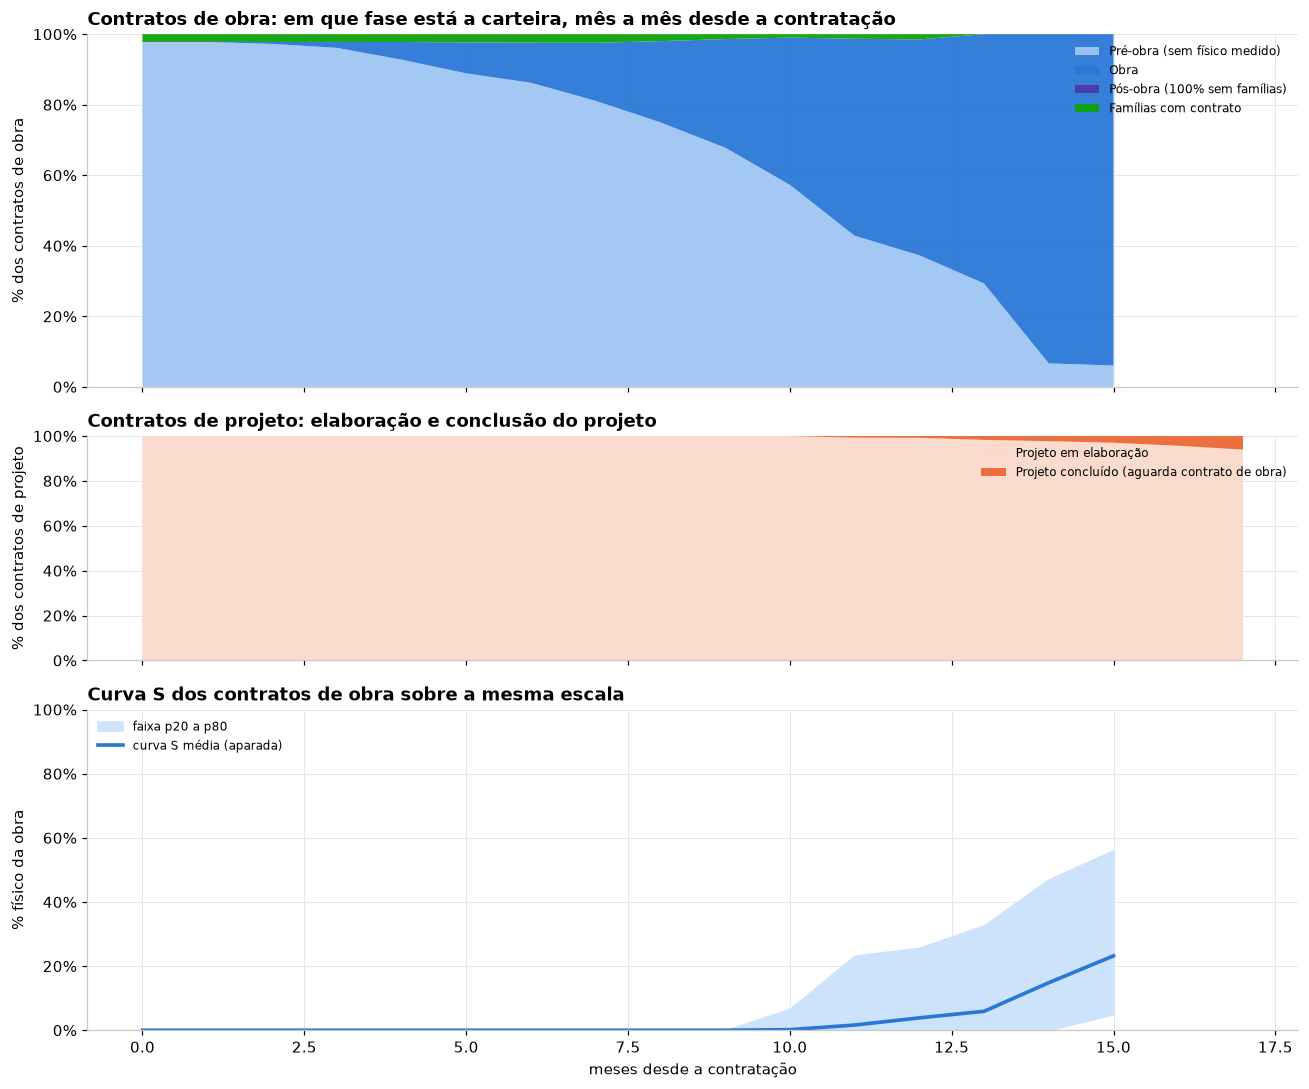

Contratos de obra: % da carteira em cada fase por mês de contrato:


fase,Pré-obra (sem físico medido),Obra,Pós-obra (100% sem famílias),Famílias com contrato
mes_contrato,,,,
0,98,0,0,2
3,96,2,0,2
6,86,11,0,2
9,68,31,0,1
12,37,61,0,1
15,6,94,0,0


Contratos de projeto:


fase,Projeto em elaboração,Projeto concluído (aguarda contrato de obra)
mes_contrato,,
0,100,0
3,100,0
6,100,0
9,100,0
12,99,1
15,97,3


In [5]:
ultimo_mes = sm.mes.max()
linhas = []
for _, r in m.dropna(subset=["dt_contratacao"]).iterrows():
    for mes in pd.date_range(r.dt_contratacao.to_period("M").to_timestamp(), ultimo_mes, freq="MS"):
        if r.fase_contrato == "PROJETO":
            fase = "Projeto concluído (aguarda contrato de obra)" if pd.notna(r.projeto_concluido) and mes >= r.projeto_concluido else "Projeto em elaboração"
        else:
            if pd.notna(r.entrada_familias) and mes >= r.entrada_familias.to_period("M").to_timestamp(): fase = "Famílias com contrato"
            elif pd.notna(r.fim_obra) and mes >= r.fim_obra: fase = "Pós-obra (100% sem famílias)"
            elif pd.notna(r.inicio_fisico) and mes >= r.inicio_fisico: fase = "Obra"
            else: fase = "Pré-obra (sem físico medido)"
        linhas.append((r.apf, r.fase_contrato, mes, fase))
grade = pd.DataFrame(linhas, columns=["apf","fase_contrato","mes","fase"]).merge(m[["apf","dt_contratacao"]], on="apf")
grade["mes_contrato"] = (grade.mes.dt.year - grade.dt_contratacao.dt.year)*12 + (grade.mes.dt.month - grade.dt_contratacao.dt.month)
ORDEM_O = ["Pré-obra (sem físico medido)", "Obra", "Pós-obra (100% sem famílias)", "Famílias com contrato"]; ORDEM_P = ["Projeto em elaboração", "Projeto concluído (aguarda contrato de obra)"]
def share(fc, ordem):
    d = grade[grade.fase_contrato == fc].pivot_table(index="mes_contrato", columns="fase", values="apf", aggfunc="nunique").fillna(0).reindex(columns=ordem, fill_value=0)
    d = d[d.sum(axis=1) >= 30]; return d.div(d.sum(axis=1), axis=0)*100
so, sp = share("OBRA", ORDEM_O), share("PROJETO", ORDEM_P)
smo = sm.merge(m[["apf","fase_contrato","dt_contratacao"]], on="apf"); smo["mes_contrato"] = (smo.mes.dt.year - smo.dt_contratacao.dt.year)*12 + (smo.mes.dt.month - smo.dt_contratacao.dt.month)
r_obra = regua(smo[(smo.fase_contrato == "OBRA") & (smo.mes_contrato >= 0)], "mes_contrato")
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1.1, 0.7, 1]})
axes[0].stackplot(so.index, [so[c] for c in ORDEM_O], labels=ORDEM_O, colors=[FASE_C[c] for c in ORDEM_O], alpha=0.95)
axes[0].set_ylim(0, 100); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[0].set_ylabel("% dos contratos de obra"); axes[0].legend(loc="upper right", fontsize=8); axes[0].set_title("Contratos de obra: em que fase está a carteira, mês a mês desde a contratação")
axes[1].stackplot(sp.index, [sp[c] for c in ORDEM_P], labels=ORDEM_P, colors=[FASE_C[c] for c in ORDEM_P], alpha=0.95)
axes[1].set_ylim(0, 100); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set_ylabel("% dos contratos de projeto"); axes[1].legend(loc="upper right", fontsize=8); axes[1].set_title("Contratos de projeto: elaboração e conclusão do projeto")
axes[2].fill_between(r_obra.index, r_obra.p20, r_obra.p80, color="#cde2fb", label="faixa p20 a p80"); axes[2].plot(r_obra.index, r_obra.media_aparada, color=C["azul"], lw=2.4, label="curva S média (aparada)")
axes[2].set_ylim(0, 100); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[2].set_ylabel("% físico da obra"); axes[2].set_xlabel("meses desde a contratação"); axes[2].legend(loc="upper left", fontsize=8); axes[2].set_title("Curva S dos contratos de obra sobre a mesma escala")
plt.tight_layout(); plt.show()
print("Contratos de obra: % da carteira em cada fase por mês de contrato:"); display(so.round(0).astype(int).loc[[i for i in [0, 3, 6, 9, 12, 15, 18] if i in so.index]])
print("Contratos de projeto:"); display(sp.round(0).astype(int).loc[[i for i in [0, 3, 6, 9, 12, 15, 18] if i in sp.index]])

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a fase de cada APF em cada mês é uma regra deste notebook</b><ul style="margin:6px 0 0 0"><li>Contratos de obra: "Obra" a partir do primeiro mês com físico medido (reserva: primeiro pagamento de obra), "Pós-obra" a partir dos 100%, "Famílias com contrato" a partir da primeira assinatura PF com UH alienada; antes disso, "Pré-obra". Contratos de projeto: "Projeto concluído" a partir dos 100%. A cláusula suspensiva ficou fora por falta de datas.</li><li>A série física tem um viés conhecido: a CAIXA informou zero para quase todos os contratos até abril de 2025, então para os contratos de 2024 o primeiro físico medido chega depois do início real; o primeiro pagamento de obra no livro-razão corrige parte disso.</li><li><b>Como levar ao banco:</b> coluna <code>fase_contrato_mes</code> na série do FDS (a criar) e a tabela <code>ouro.ouro_fds_marcos_apf</code> (um APF por linha, todos os marcos), que hoje é o parquet <code>data/interim/fds_marcos_apf.parquet</code> montado aqui.</li></ul></div>

**Leitura.** No 6º mês de contrato só um em dez contratos de obra tem físico; no 12º, seis em dez; no 15º, quase todos. A curva S só descola do zero por volta do 9º mês e está em 4% no 12º. Nos contratos de projeto, quase nenhum projeto está concluído mesmo depois do 15º mês, e é desse marco que o contrato de obra deveria nascer. Qualquer meta de entrega do Entidades precisa contar: mais de um ano de projeto, oito meses de pré-obra e, pela régua do legado, dois anos e meio de obra.

## 4. Cada contrato no calendário

Uma linha por APF, ordenada pela contratação: contratos de projeto em laranja (claro em elaboração, escuro concluído), contratos de obra em azul (claro sem físico, escuro em obra). O ponto vermelho marca os paralisados pelo INT059.

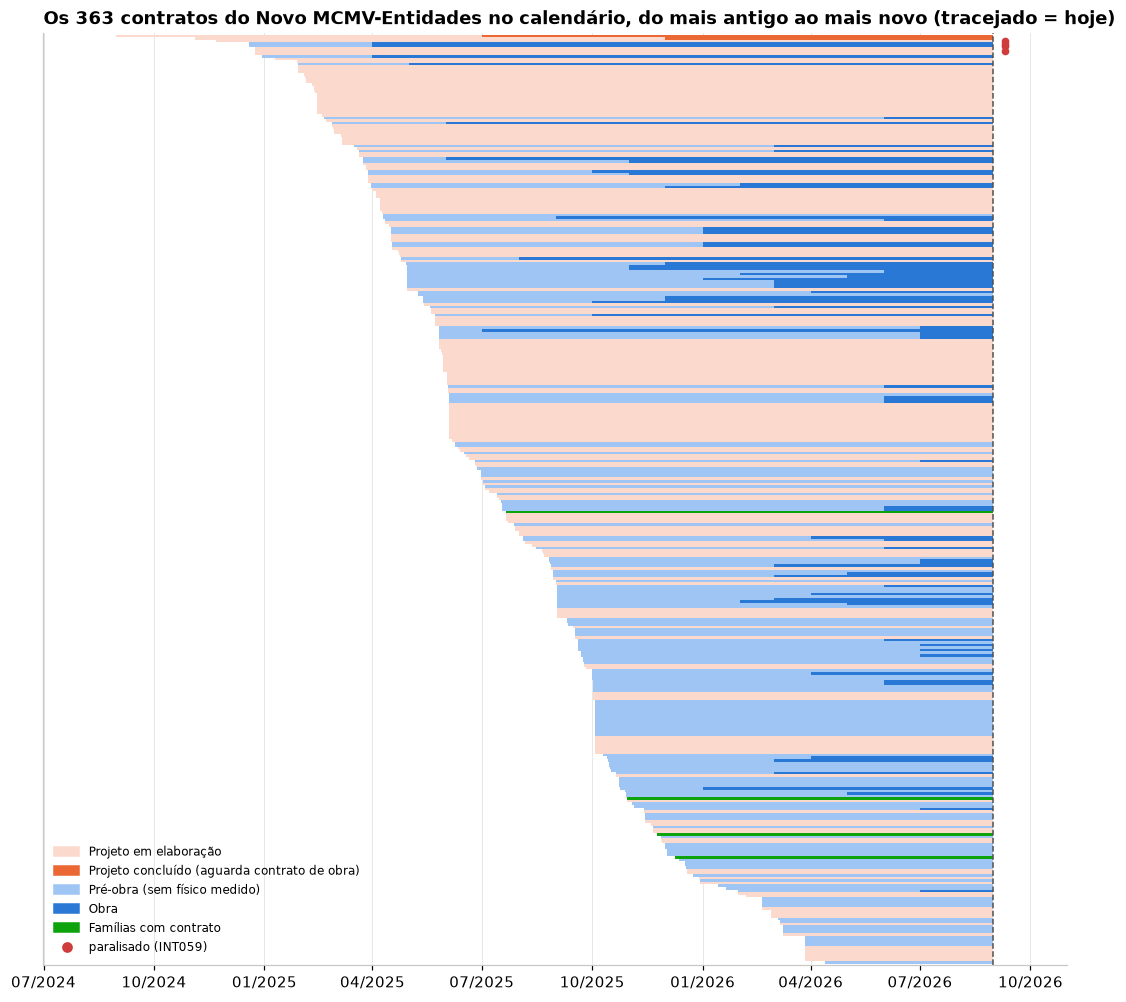

In [6]:
g = m.dropna(subset=["dt_contratacao"]).sort_values(["dt_contratacao","fase_contrato"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 11))
for i, r in g.iterrows():
    t0 = r.dt_contratacao
    if r.fase_contrato == "PROJETO":
        t1 = r.projeto_concluido if pd.notna(r.projeto_concluido) else HOJE
        ax.barh(i, (t1 - t0).days, left=t0, color=FASE_C["Projeto em elaboração"], height=1, linewidth=0)
        if pd.notna(r.projeto_concluido): ax.barh(i, (HOJE - r.projeto_concluido).days, left=r.projeto_concluido, color=FASE_C["Projeto concluído (aguarda contrato de obra)"], height=1, linewidth=0)
    else:
        t1 = max(r.inicio_fisico, t0) if pd.notna(r.inicio_fisico) else HOJE
        ax.barh(i, (t1 - t0).days, left=t0, color=FASE_C["Pré-obra (sem físico medido)"], height=1, linewidth=0)
        if pd.notna(r.inicio_fisico):
            t2 = r.fim_obra if pd.notna(r.fim_obra) else HOJE
            ax.barh(i, (t2 - t1).days, left=t1, color=FASE_C["Obra"], height=1, linewidth=0)
        if pd.notna(r.entrada_familias): ax.barh(i, (HOJE - r.entrada_familias).days, left=r.entrada_familias, color=FASE_C["Famílias com contrato"], height=1, linewidth=0)
    if r.paralisada: ax.plot(HOJE + pd.Timedelta(days=10), i, marker="o", ms=4, color=STATUS["critico"])
ax.set_ylim(-1, len(g)); ax.invert_yaxis(); ax.set_yticks([]); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.axvline(HOJE, color="#52514e", lw=1, ls="--"); ax.set_xlim(pd.Timestamp("2024-07-01"), pd.Timestamp("2026-10-31"))
ax.legend(handles=[Patch(color=FASE_C[k], label=k) for k in ["Projeto em elaboração", "Projeto concluído (aguarda contrato de obra)", "Pré-obra (sem físico medido)", "Obra", "Famílias com contrato"]] + [plt.Line2D([], [], marker="o", color=STATUS["critico"], ls="", label="paralisado (INT059)")], loc="lower left", fontsize=8)
ax.set_title(f"Os {len(g)} contratos do Novo MCMV-Entidades no calendário, do mais antigo ao mais novo (tracejado = hoje)")
plt.show()

## 5. Em que fase o atraso acontece, e o que a base diz do motivo

Para a carteira nova, a régua é a própria carteira e as regras que existem:

- **Projeto**: contrato de projeto com a promessa de conclusão vencida sem chegar a 100%, ou paralisado.
- **Pré-obra**: contrato de obra sem físico medido depois do p80 da carteira, ou em cláusula suspensiva há mais de 12 meses.
- **Obra**: abaixo da faixa p20 da curva S no último mês observado, promessa de conclusão vencida sem 100%, ou paralisado pelo INT059.
- **Pós-obra**: 100% há três meses ou mais sem famílias contratadas (ninguém chegou lá ainda).

O motivo não existe para a carteira nova: os campos do MONIT (data e classificação da paralisação, detalhe, motivo de distrato) vêm vazios para os 364 contratos, e o INT059 traz a situação sem justificativa. O motivo existe em dois lugares: nos Dados Prioritários do **legado** (`motivo_paralisacao`: a entregar, ocupado em legalização, a retomar com aporte, desimobilização, ocupação irregular) e na planilha de **trabalho social** da CAIXA (motivo do TS atrasado ou paralisado). É com eles que se responde "onde o atraso acontece mais".

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: as réguas de atraso por fase, a data de hoje e o mapa de motivo para fase</b><ul style="margin:6px 0 0 0"><li>"Projeto atrasado" = promessa vencida sem 100% ou paralisado; "pré-obra atrasada" = sem físico após o p80 da carteira ou cláusula suspensiva há mais de 12 meses; "obra atrasada" = abaixo do p20 da curva S, promessa vencida ou paralisada; "pós-obra" = 100% há 3 meses sem famílias. Regras deste notebook, data de hoje 31/08/2026.</li><li>O mapa de cada <code>motivo_paralisacao</code> do legado para uma fase (obra ou pós-obra) e o uso do motivo do trabalho social como fase própria são deste notebook.</li><li><b>Como levar ao banco:</b> modelo <code>ouro.ouro_fds_atraso_por_fase</code> com as réguas como vars do dbt e a data de posição da carga; seed <code>dominio_motivo_paralisacao_fase.csv</code> (motivo, fase) ao lado da <code>seeds.dominio_motivo_paralisacao</code>; e, para a carteira nova, o motivo só entra com a ficha do empreendimento com gestão do trabalho (ações, datas, atores), como pediu o secretário.</li></ul></div>

,contratos na fase,atrasados,UH atrasadas,FDS atrasado,% da fase atrasada
Projeto,180,110,8.269,"R$ 101,31 mi",61.000000
Pré-obra,104,56,4.102,"R$ 599,76 mi",54.000000
Obra,78,13,1.187,"R$ 183,47 mi",17.000000
Pós-obra,0,0,0,R$ 0,nan


p80 da pré-obra observada: 10.6 meses


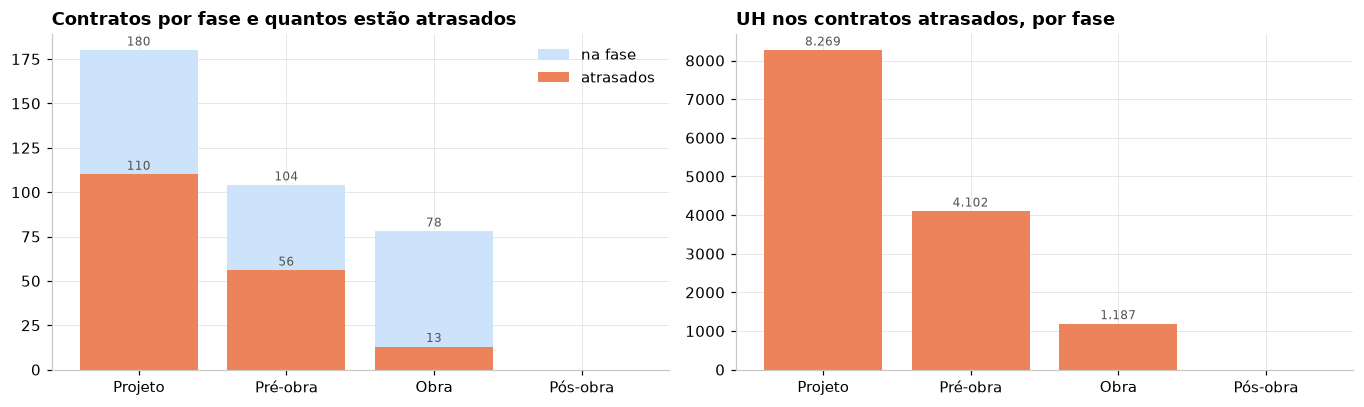

O que a base diz de cada atraso, por fase:


o_que_a_base_diz,abaixo da faixa p20,cláusula suspensiva (INT059),"paralisado (INT059), sem data nem motivo no MONIT",promessa vencida,sem físico após o p80 da carteira,All
fase_atrasada,,,,,,
Obra,5,0,2,6,0,13
Projeto,0,16,2,92,0,110
Pré-obra,0,17,0,0,39,56
All,5,33,4,98,39,179


Situação GEFUS e MONIT dos atrasados:


situacao_gefus NAO_INICIADA_CLAUSULA_SUSPENSIVA                NORMAL                                                    PARALISADA
situacao_monit                           NORMAL NÃO INICIADA ATRASADA EM ANDAMENTO NORMAL NÃO INICIADA OUTRAS PARALISADA     NORMAL
fase_atrasada                                                                                                                      
Obra                                          0            0        0            3      8            0      0          0          2
Projeto                                       2           14       15            9     36           30      1          1          2
Pré-obra                                      0           17        0            0      0           38      1          0          0

Lista completa em output/fds_contratos_atrasados_por_fase.csv


In [7]:
a = m.set_index("apf").copy()
ult = smo[smo.fase_contrato == "OBRA"].sort_values("mes").groupby("apf").tail(1).set_index("apf")[["mes_contrato","pct"]].join(r_obra[["p20"]], on="mes_contrato")
a["abaixo_p20"] = a.index.map(lambda k: ult.pct.get(k, np.nan) < ult.p20.get(k, np.nan))
a["idade"] = meses(a.dt_contratacao, pd.Series(HOJE, index=a.index)); P80_PRE = a[a.fase_contrato == "OBRA"].d_pre.quantile(.8)
a["promessa_vencida"] = (a.dt_previsao_conclusao < HOJE) & a.m_100.isna()
a["atraso_proj"] = (a.fase_contrato == "PROJETO") & a.projeto_concluido.isna() & (a.promessa_vencida | a.paralisada)
a["atraso_pre"] = (a.fase_contrato == "OBRA") & a.inicio_fisico.isna() & ((a.idade > P80_PRE) | (a.susp & (a.idade > 12)))
a["atraso_obra"] = (a.fase_contrato == "OBRA") & a.inicio_fisico.notna() & a.fim_obra.isna() & (a.abaixo_p20 | a.promessa_vencida | a.paralisada)
a["atraso_pos"] = (a.fase_contrato == "OBRA") & a.fim_obra.notna() & a.entrada_familias.isna() & (meses(a.fim_obra, pd.Series(HOJE, index=a.index)) >= 3)
na_fase = {"Projeto": ((a.fase_contrato == "PROJETO") & a.projeto_concluido.isna()).sum(), "Pré-obra": ((a.fase_contrato == "OBRA") & a.inicio_fisico.isna()).sum(),
           "Obra": ((a.fase_contrato == "OBRA") & a.inicio_fisico.notna() & a.fim_obra.isna()).sum(), "Pós-obra": ((a.fase_contrato == "OBRA") & a.fim_obra.notna() & a.entrada_familias.isna()).sum()}
atr = {"Projeto": a.atraso_proj, "Pré-obra": a.atraso_pre, "Obra": a.atraso_obra, "Pós-obra": a.atraso_pos}
resumo = pd.DataFrame({"contratos na fase": pd.Series(na_fase), "atrasados": {k: v.sum() for k, v in atr.items()}, "UH atrasadas": {k: a.loc[v, "quantidade_uh"].sum() for k, v in atr.items()}, "FDS atrasado": {k: a.loc[v, "valor_financiamento_fds"].sum() for k, v in atr.items()}})
resumo["% da fase atrasada"] = (100*resumo.atrasados/resumo["contratos na fase"]).round(0)
display(resumo.style.format({"UH atrasadas": num, "FDS atrasado": brl}))
print(f"p80 da pré-obra observada: {P80_PRE:.1f} meses")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].bar(resumo.index, resumo["contratos na fase"], color="#cde2fb", label="na fase"); axes[0].bar(resumo.index, resumo.atrasados, color=STATUS["serio"], label="atrasados"); axes[0].set_title("Contratos por fase e quantos estão atrasados"); axes[0].legend(); rotular_barras(axes[0], fontsize=8)
axes[1].bar(resumo.index, resumo["UH atrasadas"], color=STATUS["serio"]); axes[1].set_title("UH nos contratos atrasados, por fase"); rotular_barras(axes[1], fontsize=8)
plt.tight_layout(); plt.show()
a["fase_atrasada"] = np.select([a.atraso_proj, a.atraso_pre, a.atraso_obra, a.atraso_pos], ["Projeto", "Pré-obra", "Obra", "Pós-obra"], default="")
a["o_que_a_base_diz"] = np.select([a.paralisada, a.susp, a.promessa_vencida & a.abaixo_p20.fillna(False), a.promessa_vencida, (a.fase_contrato == "OBRA") & a.inicio_fisico.isna(), a.abaixo_p20.fillna(False)],
                                  ["paralisado (INT059), sem data nem motivo no MONIT", "cláusula suspensiva (INT059)", "promessa vencida e abaixo da faixa", "promessa vencida", "sem físico após o p80 da carteira", "abaixo da faixa p20"], "")
lista = a[a.fase_atrasada != ""]
print("O que a base diz de cada atraso, por fase:"); display(pd.crosstab(lista.fase_atrasada, lista.o_que_a_base_diz, margins=True))
print("Situação GEFUS e MONIT dos atrasados:"); display(pd.crosstab(lista.fase_atrasada, [lista.situacao_gefus, lista.situacao_monit]))
lista.reset_index()[["apf","empreendimento_nome","municipio","uf","eo_nome","fase_contrato","fase_atrasada","o_que_a_base_diz","quantidade_uh","valor_financiamento_fds","dt_contratacao","inicio_fisico","dt_previsao_conclusao","pct_ult","percentual_obra_prevista","percentual_execucao_financeira","situacao_gefus","situacao_monit"]].sort_values(["fase_atrasada","dt_contratacao"]).to_csv(OUT / "fds_contratos_atrasados_por_fase.csv", index=False)
print("Lista completa em output/fds_contratos_atrasados_por_fase.csv")

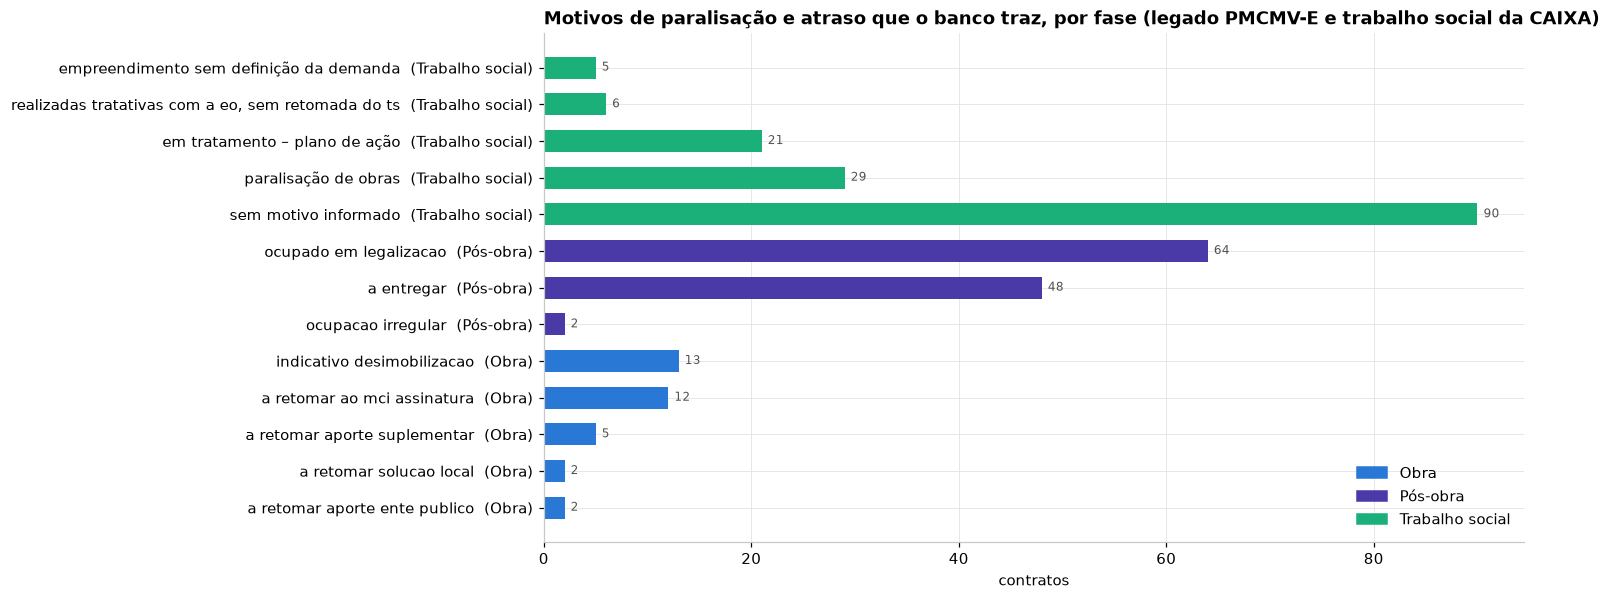

,contratos,uh
fase,,
Obra,34,5174.0
Pós-obra,114,19612.0
Trabalho social,151,0.0


No legado, 77% dos contratos com motivo registrado estão parados depois da obra (a entregar, legalização, ocupação irregular), não durante.


In [8]:
# Onde o atraso acontece mais, pelos motivos que o banco traz: legado (Dados Prioritários) e trabalho social (CAIXA)
legs = cache("fds_legado_snh_motivo", """
select distinct on (apf) apf, status_operacional, motivo_paralisacao, quantidade_uh, percentual_execucao_fisica, dt_referencia
from prata.prata_hist_fds_empreendimento where fonte_serie = 'snh' and motivo_paralisacao is not null and motivo_paralisacao <> 'em_andamento' order by apf, dt_referencia desc""")
FASE_MOTIVO = {"a_entregar": "Pós-obra", "ocupado_em_legalizacao": "Pós-obra", "ocupacao_irregular": "Pós-obra", "a_retomar": "Obra", "a_retomar_ao_mci_assinatura": "Obra", "a_retomar_aporte_suplementar": "Obra",
               "a_retomar_aporte_ente_publico": "Obra", "a_retomar_solucao_local": "Obra", "a_retomar_em_analise": "Obra", "a_retomar_em_construcao_proposta": "Obra", "indicativo_desimobilizacao": "Obra", "desimobilizacao_assinada": "Obra", "reducao_de_meta": "Obra"}
legs["fase"] = legs.motivo_paralisacao.map(FASE_MOTIVO).fillna("Obra")
mot = legs.groupby(["fase","motivo_paralisacao"]).agg(contratos=("apf","size"), uh=("quantidade_uh","sum")).reset_index().sort_values(["fase","contratos"])
tsb = cache("fds_ts_caixa_202607", """select contrato, municipio, uf, nome_empreendimento, uh, fase_mcmv, situacao_ts, motivo_situacao_ts_atrasado_paralisado, execucao_ts, obra,
       vr_global_ts, vr_desembolsado, natureza_execucao, instrumento_de_planejamento, data_da_contratacao from bronze.bronze_shpt_mcmv_fds_ts_caixa_202607""")
tsm = tsb[tsb.situacao_ts.isin(["ATRASADO","PARALISADO"])].motivo_situacao_ts_atrasado_paralisado.replace("", np.nan).fillna("sem motivo informado").str.lower().value_counts().reset_index()
tsm.columns = ["motivo_paralisacao","contratos"]; tsm["fase"] = "Trabalho social"; tsm["uh"] = np.nan
todos = pd.concat([mot, tsm[["fase","motivo_paralisacao","contratos","uh"]]]).reset_index(drop=True)
todos["rotulo"] = todos.motivo_paralisacao.str.replace("_", " ")
COR_F = {"Obra": C["azul"], "Pós-obra": C["roxo"], "Trabalho social": C["verde"]}
fig, ax = plt.subplots(figsize=(11.5, 6))
ax.barh(todos.rotulo + "  (" + todos.fase + ")", todos.contratos, color=[COR_F[f] for f in todos.fase], height=0.6)
ax.set_xlabel("contratos"); ax.set_title("Motivos de paralisação e atraso que o banco traz, por fase (legado PMCMV-E e trabalho social da CAIXA)")
ax.legend(handles=[Patch(color=v, label=k) for k, v in COR_F.items()], loc="lower right"); rotular_barras(ax, horizontal=True, fontsize=8)
plt.show()
res = todos.groupby("fase").agg(contratos=("contratos","sum"), uh=("uh","sum")); display(res)
print(f"No legado, {100*res.loc['Pós-obra','contratos']/(res.loc['Pós-obra','contratos'] + res.loc['Obra','contratos']):.0f}% dos contratos com motivo registrado estão parados depois da obra (a entregar, legalização, ocupação irregular), não durante.")

**Leitura.** Na carteira nova o atraso está na fase de projeto e na pré-obra: 92 contratos de projeto já passaram da promessa sem o projeto pronto, e 56 contratos de obra estão sem físico além do p80 da carteira (10,6 meses), 17 deles em cláusula suspensiva há mais de um ano. Na obra propriamente dita, os 13 atrasados são os que estão abaixo da faixa, passaram da promessa ou os dois paralisados de João Pessoa. O legado inverte a intuição: dos contratos parados com motivo registrado, três em cada quatro pararam **depois** da obra, "a entregar" ou "ocupado em legalização", não durante; o pós-obra é a fase onde o Entidades mais trava, porque a legalização e a alienação dependem de cartório, prefeitura e da própria entidade. No trabalho social, o motivo mais comum é a paralisação da obra, seguido de "em tratamento com plano de ação". Para a carteira nova, nada disso está registrado: é o vazio que a ficha do empreendimento com gestão do trabalho precisa preencher.

## 6. O caso da União por Moradia Popular da Paraíba (UMP-PB)

Oito contratos em João Pessoa, Bayeux, Sapé e Mari (999 UH): um projeto concluído (Residencial Antonio Junior, 50 UH, o primeiro contrato do Novo MCMV-Entidades no país, de 30/08/2024) e duas obras de 256 UH cada (Jardim do Sul e Morada do Sul, contratadas no mesmo dia, 19/12/2024) que o INT059 marca como **paralisadas** em junho de 2026, enquanto o MONIT as chama de normais e o livro-razão segue liberando todo mês.

,apf,empreendimento_nome,municipio,fase_contrato,situacao_gefus,situacao_monit,quantidade_uh,dt_contratacao,dt_previsao_conclusao,inicio_fisico,pct_ult,percentual_obra_prevista,percentual_execucao_financeira,valor_financiamento_fds,valor_desembolsado,situacao_ts,execucao_ts
0,63531778,RESIDENCIAL ANTONIO JUNIOR,JOÃO PESSOA,PROJETO,CONCLUIDA,CONCLUÍDA,50,30/08/2024,30/09/2025,11/2024,100.0%,79.0%,100.0%,"R$ 397,70 mil","R$ 397,70 mil",CONCLUIDO,100
1,63531550,RESIDENCIAL JARDIM DO SUL,JOÃO PESSOA,OBRA,PARALISADA,NORMAL,256,19/12/2024,19/11/2026,04/2025,40.2%,39.9%,44.9%,"R$ 43,09 mi","R$ 19,33 mi",EM ANDAMENTO,64.36
2,63531664,RESIDENCIAL MORADA DO SUL,JOÃO PESSOA,OBRA,PARALISADA,NORMAL,256,19/12/2024,19/11/2026,04/2025,29.0%,32.3%,35.8%,"R$ 43,52 mi","R$ 15,58 mi",EM ANDAMENTO,59.09
3,63530648,DIANA GUERRA I,BAYEUX,OBRA,NORMAL,NORMAL,56,11/04/2025,13/03/2028,06/2026,0.0%,0.0%,9.5%,"R$ 7,84 mi","R$ 1,28 mi",EM ANDAMENTO,20.97
4,63531996,RESIDENCIAL BOM VIVER EM MARI,MARI,OBRA,NORMAL,EM ANDAMENTO,95,09/05/2025,10/05/2027,04/2026,13.0%,11.8%,25.6%,"R$ 13,59 mi","R$ 3,60 mi",EM ANDAMENTO,16.99
5,63532806,RESIDENCIAL ANTONIO CABRAL DE CASTRO,SAPÉ,OBRA,NORMAL,NÃO INICIADA,150,09/05/2025,09/05/2027,–,0.0%,0.0%,0.0%,"R$ 21,45 mi",R$ 0,EM ANDAMENTO,
6,63530429,DIANA GUERRA II,BAYEUX,OBRA,NORMAL,NÃO INICIADA,112,09/06/2025,09/06/2027,–,0.0%,0.0%,0.0%,"R$ 15,68 mi",R$ 0,EM ANDAMENTO,
7,63530534,DIANA GUERRA III,BAYEUX,OBRA,NORMAL,NÃO INICIADA,24,09/06/2025,09/06/2027,–,0.0%,0.0%,0.0%,"R$ 3,36 mi",R$ 0,EM ANDAMENTO,


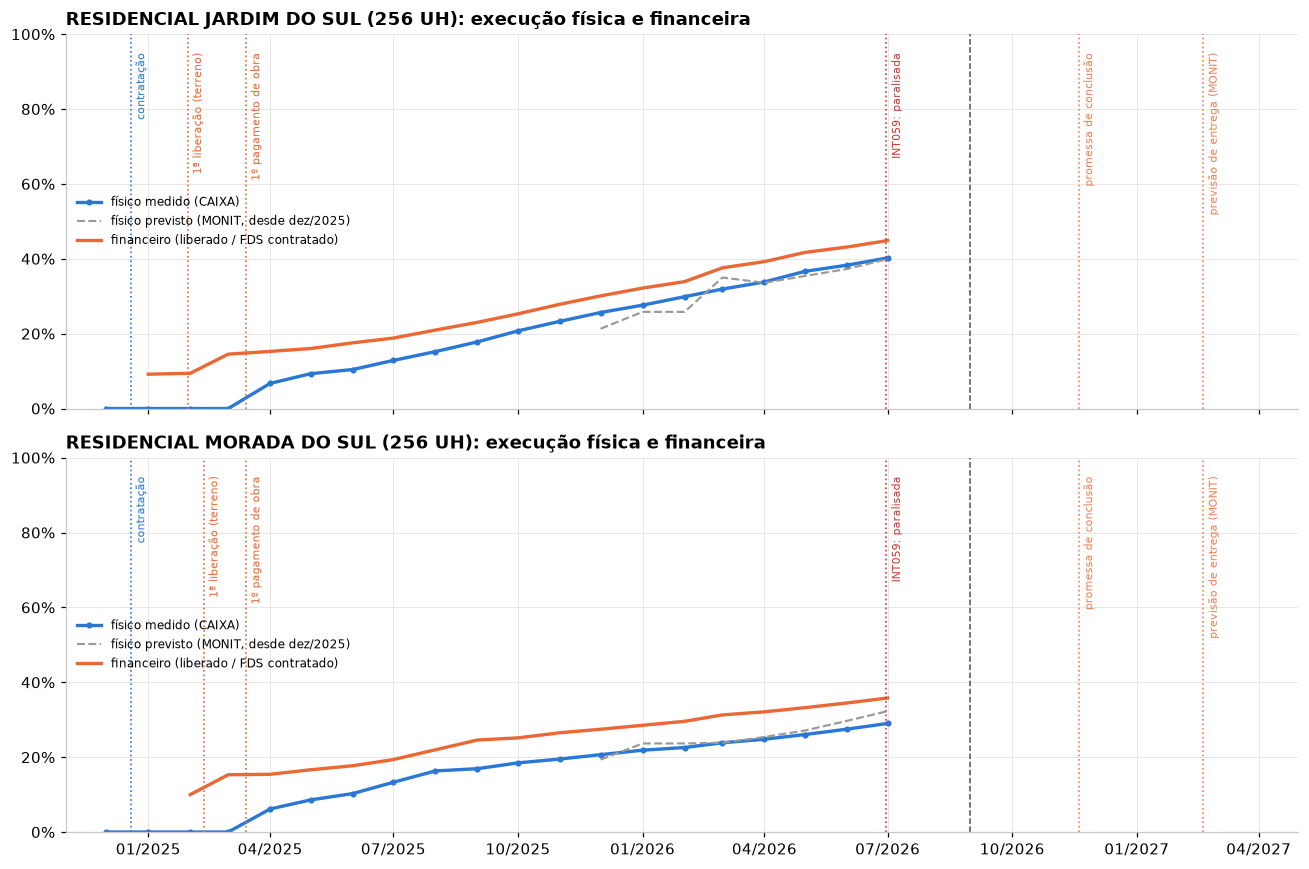

RESIDENCIAL JARDIM DO SUL: 40.2% em 07/2026; ritmo dos últimos 12 meses 2.3 p.p./mês; a esse ritmo os 100% chegam em 09/2028 (promessa: 11/2026); liberado R$ 19,33 mi de R$ 43,09 mi
RESIDENCIAL MORADA DO SUL: 29.0% em 07/2026; ritmo dos últimos 12 meses 1.3 p.p./mês; a esse ritmo os 100% chegam em 01/2031 (promessa: 11/2026); liberado R$ 15,58 mi de R$ 43,52 mi


In [9]:
u = m[m.eo_nome.str.contains("UMP-PB", na=False)].sort_values("dt_contratacao")
tsb["apf"] = tsb.contrato.str.replace(r"[^0-9]", "", regex=True).str.zfill(8)
u = u.merge(tsb[["apf","situacao_ts","execucao_ts"]], on="apf", how="left")
display(u[["apf","empreendimento_nome","municipio","fase_contrato","situacao_gefus","situacao_monit","quantidade_uh","dt_contratacao","dt_previsao_conclusao","inicio_fisico","pct_ult","percentual_obra_prevista","percentual_execucao_financeira","valor_financiamento_fds","valor_desembolsado","situacao_ts","execucao_ts"]].style.format({"dt_contratacao": "{:%d/%m/%Y}", "dt_previsao_conclusao": "{:%d/%m/%Y}", "inicio_fisico": "{:%m/%Y}", "valor_financiamento_fds": brl, "valor_desembolsado": brl, "pct_ult": "{:.1f}%", "percentual_obra_prevista": "{:.1f}%", "percentual_execucao_financeira": "{:.1f}%"}, na_rep="–"))
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
for ax, apf in zip(axes, ["63531550", "63531664"]):
    r = m.set_index("apf").loc[apf]
    s = sm[sm.apf == apf].sort_values("mes"); f = fin[fin.apf_raiz == apf[:6]].set_index("dt_liberacao").resample("MS").liberado.sum().cumsum()/r.valor_financiamento_fds*100
    ax.plot(s.mes, s.pct, color=C["azul"], lw=2.2, marker="o", ms=3, label="físico medido (CAIXA)")
    ax.plot(s.mes, s.pct_prev, color=C["cinza"], lw=1.4, ls="--", label="físico previsto (MONIT, desde dez/2025)")
    ax.plot(f.index, f.values, color=C["laranja"], lw=2.2, label="financeiro (liberado / FDS contratado)")
    for d, rot, cor in [(r.dt_contratacao, "contratação", C["azul"]), (r.m_lib0, "1ª liberação (terreno)", C["laranja"]), (r.m_obra0, "1º pagamento de obra", C["laranja"]), (pd.Timestamp("2026-06-30"), "INT059: paralisada", STATUS["critico"]), (r.dt_previsao_conclusao, "promessa de conclusão", STATUS["serio"]), (r.prev_ent_monit, "previsão de entrega (MONIT)", STATUS["serio"])]:
        if pd.notna(d): ax.axvline(d, color=cor, lw=1.1, ls=":"); ax.annotate(rot, (d, 95), xytext=(3, 0), textcoords="offset points", fontsize=7.5, rotation=90, va="top", color=cor)
    ax.axvline(HOJE, color="#52514e", lw=1, ls="--")
    ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc="center left", fontsize=8); ax.set_title(f"{r.empreendimento_nome} ({r.quantidade_uh} UH): execução física e financeira")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y")); axes[1].set_xlim(pd.Timestamp("2024-11-01"), pd.Timestamp("2027-04-30"))
plt.tight_layout(); plt.show()
for apf in ["63531550", "63531664"]:
    s = sm[sm.apf == apf].sort_values("mes"); r = m.set_index("apf").loc[apf]
    ritmo = (s.pct.iloc[-1] - s[s.mes <= s.mes.max() - pd.DateOffset(months=12)].pct.iloc[-1]) / 12
    print(f"{r.empreendimento_nome}: {s.pct.iloc[-1]:.1f}% em {s.mes.max():%m/%Y}; ritmo dos últimos 12 meses {ritmo:.1f} p.p./mês; a esse ritmo os 100% chegam em {(s.mes.max() + pd.DateOffset(months=int((100 - s.pct.iloc[-1])/ritmo))):%m/%Y} (promessa: {r.dt_previsao_conclusao:%m/%Y}); liberado {brl(r.valor_desembolsado)} de {brl(r.valor_financiamento_fds)}")

**O que aconteceu com Jardim do Sul e Morada do Sul.** A cronologia que os dados contam:

1. Contratados em 19/12/2024, ambos receberam a primeira parcela em janeiro e fevereiro de 2025 (R$ 3,95 mi e R$ 4,35 mi, inteiramente terreno) e o primeiro pagamento de obra em março de 2025. O físico aparece em abril de 2025 (6 a 7%), um trimestre depois do contrato: a pré-obra aqui foi curta.
2. Desde então a obra anda a 1 ou 2 pontos percentuais por mês, com liberações mensais de R$ 0,5 a 1 milhão. O previsto do MONIT, que só existe desde dezembro de 2025, acompanha o realizado de perto: pelo cronograma vigente, as duas obras estão em dia.
3. Em junho de 2026 o INT059 muda a situação para "paralisada". Nada mais muda: o MONIT de julho segue "normal", o físico sobe, o livro-razão libera em junho e em julho, o trabalho social está "em andamento" com 60% de execução. Não há data, classificação nem detalhe da paralisação em nenhum campo.
4. O problema real não é a paralisação, é o ritmo: a 2,3 pontos por mês no Jardim do Sul e 1,3 no Morada do Sul, as obras chegam a 100% em 2028 e em 2031, anos depois da promessa (novembro de 2026) e da previsão de entrega do MONIT (fevereiro de 2027). O cronograma vigente foi reprogramado para o ritmo real, por isso "está em dia".

A lição para o painel: no Entidades, "paralisada" no INT059 precisa ser lida contra o livro-razão e a medição, porque pode ser um marcador administrativo (ou um atraso de atualização) e não uma obra parada; e a régua que importa é a da promessa original, não o cronograma reprogramado. Para saber o que o INT059 quis dizer, só perguntando à GIHAB de João Pessoa ou olhando os ofícios, que é exatamente o que o secretário chamou de "a Caixa do FDS é uma bagunça".

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a leitura do caso é interpretação sobre dados do banco</b><ul style="margin:6px 0 0 0"><li>Datas, valores e situações são do banco. A conclusão de que a "paralisação" do INT059 não corresponde a uma obra parada é inferência a partir do físico, do livro-razão e do MONIT; o banco não diz o que a CAIXA registrou nem por quê. A projeção de 100% em 2028 extrapola o ritmo dos últimos 12 meses.</li><li><b>Como fechar:</b> confirmar com a GIHAB de João Pessoa ou com o DPSM; e, no banco, um indicador "situação divergente entre fontes" (INT059 x MONIT x livro-razão) na ficha, para casos assim aparecerem sozinhos.</li></ul></div>

## 7. Síntese

- O contrato do Entidades tem uma fase a mais que o FAR, o projeto, e ela já passa de um ano para os 180 contratos ainda em elaboração; 103 contratos de obra não têm físico, 38 deles em cláusula suspensiva. Pela régua do legado, do contrato de projeto à entrega são quatro anos ou mais.
- A curva S da obra só descola do zero no 9º mês de contrato; a carteira nova ainda não tem obra concluída e a mediana do físico entre as iniciadas é de 13%.
- O atraso da carteira nova está no projeto (110 contratos) e na pré-obra (56), não na obra (13). No legado, três em cada quatro contratos parados com motivo registrado pararam depois da obra: legalização e entrega são o gargalo histórico do Entidades.
- A base não traz motivo de atraso para a carteira nova em nenhuma fase; o motivo só existe no legado (Dados Prioritários) e no trabalho social (planilha da CAIXA, ainda na bronze).
- O INT059 marca quatro contratos paralisados, mas no caso da UMP-PB o físico, o financeiro e o MONIT dizem que a obra anda; o que há é um ritmo que leva a 100% dois anos depois da promessa.
- Próximo passo: ligar os APFs de projeto e de obra do mesmo empreendimento (vínculo que o GEFUS tem na planilha de fases) para medir o tempo entre os dois contratos, e usar a planilha de trabalho social como modelo do motivo que a obra precisa ter.